# Data integration and batch correction with SIMBA

[SIMBA](https://www.nature.com/articles/s41592-023-01899-8) (**SI**ngle-cell
e**MB**edding **A**long with features) embeds cells *and* features (genes,
and optionally peaks / motifs / k-mers) into one shared latent space by
training a knowledge-graph embedding on a typed graph of cell&ndash;gene
(and, for batch integration, cell&ndash;cell) edges, with PyTorch-BigGraph
(PBG) as the training engine.

**This tutorial uses omicverse's own native SIMBA** (`ov.ge.SIMBA`, merged in
PR #1094): a from-scratch, pure-PyTorch re-implementation of SIMBA's graph
construction, preprocessing and PBG-style training. There is nothing to
install &mdash; no `simba`, no `simba_pbg`, no `torchbiggraph`. A GPU speeds
training up but is optional; everything below also runs on CPU.
`ov.single.pySIMBA` keeps the familiar `preprocess` / `gen_graph` / `train` /
`batch_correction` API for anyone coming from the original SIMBA tutorials,
and we also show the lower-level `ov.ge.SIMBA` API it is built on, which
exposes graph statistics, training history, and the gene/cell co-embedding
analysis functions directly.

Paper: [SIMBA: single-cell embedding along with features](https://www.nature.com/articles/s41592-023-01899-8), Chen *et al.*, *Nature Methods* 2023.

**Data.** The original version of this tutorial batch-corrected three human
pancreas studies bundled by the SIMBA authors on figshare; that download link
is behind a bot-challenge wall unreachable from this network at the time of
writing. We use the same batch-integration task `ov.ge.SIMBA`'s own parity
benchmark against the original SIMBA/PBG was validated on instead: three
donors (`s1d3`, `s2d1`, `s3d7`) of real bone-marrow mononuclear cells from
the [NeurIPS 2021 Multimodal Single-Cell Integration
competition](https://openproblems.bio/neurips_docs/data/dataset/), the same
dataset `Tutorials-single/batch/t_single_batch.ipynb` uses for its other
batch-correction methods.

In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import omicverse as ov
import tqdm.auto, tqdm.std
tqdm.auto.tqdm = tqdm.std.tqdm  # plain-text progress bar (renders correctly in a saved notebook)
ov.utils.ov_plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 2
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0
    • [CUDA 1] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.4.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## Load data

Real counts, three donors, downloaded once and cached locally by
`ov.datasets.get_adata` (re-run-safe: if the file is already on disk it is
loaded, not re-downloaded). `s2d1` and `s3d7` are subsampled to 8,000 cells
(fixed seed) to match the batch-integration setup used in `ov.ge.SIMBA`'s own
parity check against the original SIMBA/PBG (see the last section); `s1d3`
(5,935 cells) is kept as-is. `.X` in these files is already normalized, so we
restore the raw UMI counts SIMBA's own preprocessing expects from
`layers['counts']`.

In [2]:
urls = {'s1d3': ('https://figshare.com/ndownloader/files/41932005', None),
        's2d1': ('https://figshare.com/ndownloader/files/41932011', 8000),
        's3d7': ('https://figshare.com/ndownloader/files/41932008', 8000)}
donors, rng = {}, np.random.default_rng(0)
for name, (url, cap) in urls.items():
    a = ov.datasets.get_adata(url, f'neurips2021_{name}.h5ad')
    a.X, a.obs['batch'] = a.layers['counts'].copy(), name
    if cap is not None and a.n_obs > cap:
        a = a[np.sort(rng.choice(a.n_obs, cap, replace=False))].copy()
    donors[name] = a

⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes


⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [3]:
adata = ad.concat(donors.values(), index_unique='-')
adata.obs['cell_type'] = adata.obs['cell_type'].astype('category')
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 21935 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts', None (.X)

In [4]:
adata.obs[['batch', 'cell_type']].value_counts().unstack('batch').fillna(0).astype(int).iloc[:10]

batch                         s1d3  s2d1  s3d7
cell_type                                     
B1 B IGKC+                      41    69    63
B1 B IGKC-                      48    40    36
CD4+ T activated               547   546   284
CD4+ T activated integrinB7+   141    87     0
CD4+ T naive                   833   698   158
CD8+ T CD49f+                   49    52    12
CD8+ T CD57+ CD45RA+           251    24     0
CD8+ T CD69+ CD45RA+            33    72     0
CD8+ T CD69+ CD45RO+            32    65    33
CD8+ T TIGIT+ CD45RO+           37    89     0

## Part 1 &mdash; the `ov.single.pySIMBA` workflow

This is the same four-call workflow (`preprocess` &rarr; `gen_graph` &rarr;
`train` &rarr; `batch_correction`) as the original SIMBA tutorials. Nothing
in the public API changed; `simba_object.simba_model` underneath is now a
plain `ov.ge.SIMBA` instance trained with `ov.ge`'s own PyTorch optimiser
instead of spawning PBG's Hogwild worker processes.

In [5]:
workdir = 'result_bmmc_simba'
simba_object = ov.single.pySIMBA(adata, workdir)
simba_object.preprocess(batch_key='batch', min_n_cells=3,
                        method='lib_size', n_top_genes=3000, n_bins=5)


🔍 Highly Variable Genes Selection:
   Method: seurat_v3
   Target genes: 3,000

╭─ SUMMARY: highly_variable_genes ───────────────────────────────────╮
│  Duration: 0.0809s                                                 │
│  Shape:    5,935 x 13,953 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ _ov_provenance                                       │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯



🔍 Highly Variable Genes Selection:
   Method: seurat_v3
   Target genes: 3,000

╭─ SUMMARY: highly_variable_genes ───────────────────────────────────╮
│  Duration: 0.074s                                                  │
│  Shape:    8,000 x 13,953 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ _ov_provenance                                       │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯



🔍 Highly Variable Genes Selection:
   Method: seurat_v3
   Target genes: 3,000

╭─ SUMMARY: highly_variable_genes ───────────────────────────────────╮
│  Duration: 0.0776s                                                 │
│  Shape:    8,000 x 13,953 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ _ov_provenance                                       │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯


`preprocess` library-size normalises, log-transforms, selects the top 3,000
highly variable genes (Seurat v3 `vst`) and discretizes expression into 5
levels &mdash; independently per batch, exactly as the original SIMBA
recipe does.

`gen_graph` then infers mutual-nearest-neighbour cell&ndash;cell edges
between the largest batch (the automatic reference) and every other batch,
and builds the full cell&ndash;gene + cell&ndash;cell graph.

In [6]:
simba_object.gen_graph()
simba_object.simba_model.graph

#shared features: 3000
Performing randomized SVD ...


Searching for mutual nearest neighbors ...


38367 edges are selected
#shared features: 3000
Performing randomized SVD ...


Searching for mutual nearest neighbors ...


54121 edges are selected


HeteroGraph(entities=[G=4845, s1d3=5935, s2d1=8000, s3d7=8000], relations=17, edges=6354515)

## Training

No `dict_config['workers']`, no PBG config file, no spawned worker
processes: `train()` runs `ov.ge`'s own vectorised epoch loop (GPU if one is
visible, CPU otherwise) with SIMBA/PBG's own defaults (dimension 50, 10
epochs, softmax loss over dot-product scores, 50 batch + 50 uniform
negatives per edge, PBG's sample-size-scaled automatic weight decay). This
is the one expensive cell in the notebook (minutes, not seconds &mdash; a
6.3-million-edge graph).

In [7]:
simba_object.train()

ov.ge fit:   0%|          | 0/10 [00:00<?, ?it/s]

ov.ge fit:   0%|          | 0/10 [00:09<?, ?it/s, loss=22.5501]

ov.ge fit:  10%|█         | 1/10 [00:09<01:27,  9.68s/it, loss=22.5501]

ov.ge fit:  10%|█         | 1/10 [00:19<01:27,  9.68s/it, loss=21.8465]

ov.ge fit:  20%|██        | 2/10 [00:19<01:16,  9.61s/it, loss=21.8465]

ov.ge fit:  20%|██        | 2/10 [00:28<01:16,  9.61s/it, loss=21.7611]

... (12 outputs left out)

ov.ge fit:  90%|█████████ | 9/10 [01:26<00:09,  9.54s/it, loss=21.4421]

ov.ge fit:  90%|█████████ | 9/10 [01:35<00:09,  9.54s/it, loss=21.3722]

ov.ge fit: 100%|██████████| 10/10 [01:35<00:00,  9.52s/it, loss=21.3722]

ov.ge fit: 100%|██████████| 10/10 [01:35<00:00,  9.55s/it, loss=21.3722]

## Batch correction

`batch_correction()` projects every non-reference batch's embedding onto the
reference batch's space by a softmax-weighted average over reference cells
(`ov.ge.embed`, SIMBA's own `tl.embed`/`tl.softmax`), and writes the result
into `adata.obsm['X_simba']`.

In [8]:
adata = simba_object.batch_correction()
adata.obsm['X_simba'].shape

(21935, 50)

## Visualize

`mde` (minimum-distortion embedding) in place of UMAP, as in the original
tutorial, then UMAP on the same `X_simba` representation.

In [9]:
from omicverse.utils import mde
adata.obsm['X_mde'] = mde(adata.obsm['X_simba'])

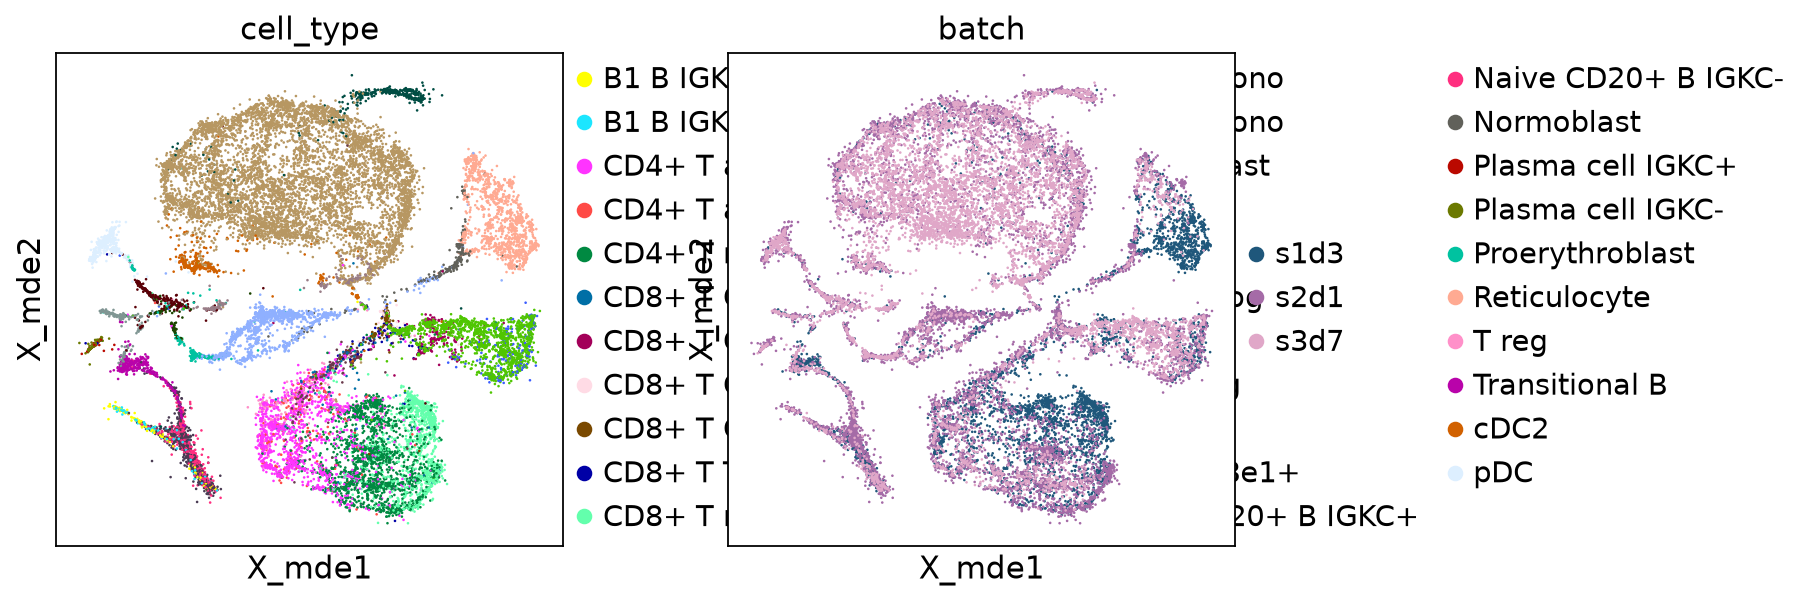

In [10]:
import scanpy as sc
sc.pl.embedding(adata, basis='X_mde', color=['cell_type', 'batch'])

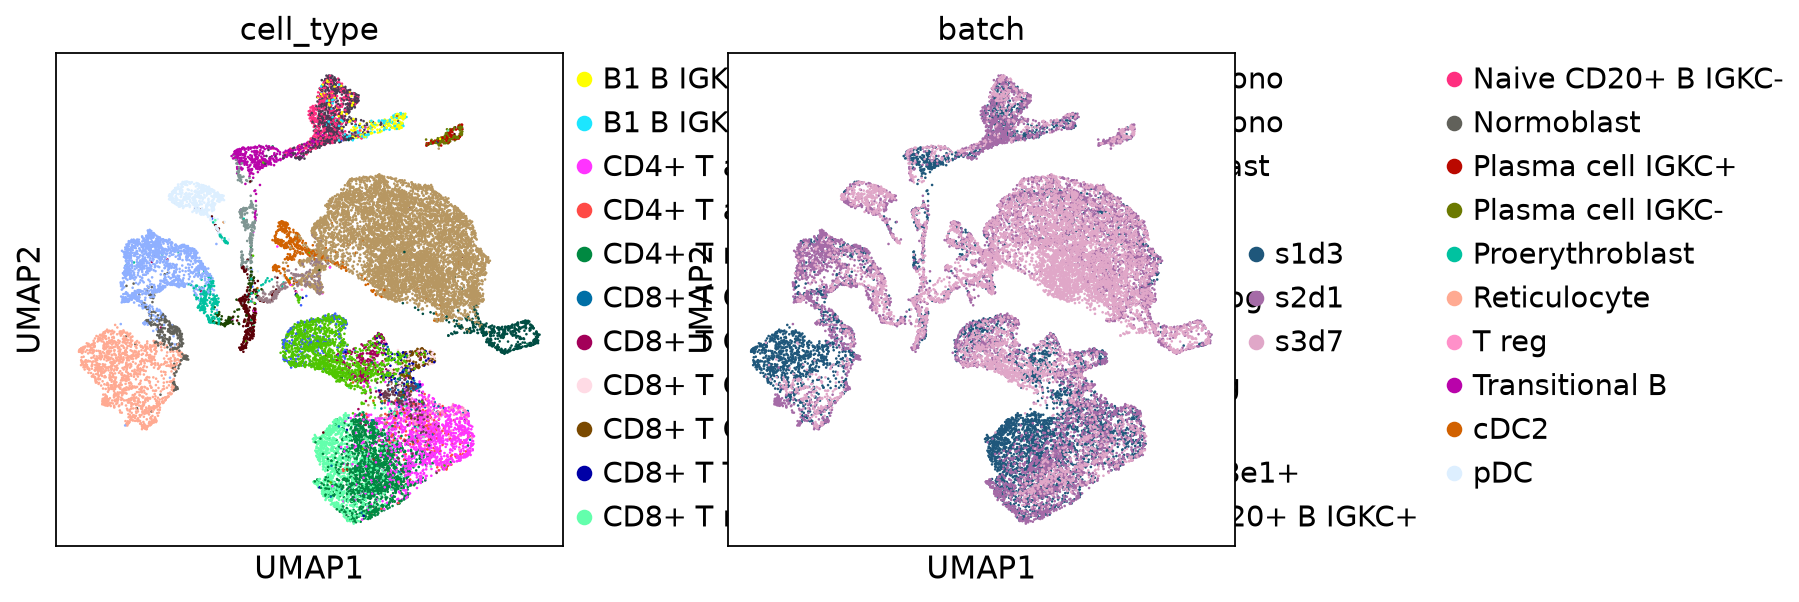

In [11]:
sc.pp.neighbors(adata, use_rep='X_simba')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['cell_type', 'batch'])

## Part 2 &mdash; the direct `ov.ge.SIMBA` API

`simba_object.simba_model` *is* the `ov.ge.SIMBA` object `gen_graph()` built
and `train()` trained above &mdash; everything below works on it directly,
no re-training needed. This is what `ov.single.pySIMBA` calls under the
hood, exposed for users who want graph statistics, the training curve, or
SIMBA's gene/cell co-embedding analysis without going through the wrapper.

In [12]:
model = simba_object.simba_model
entity_counts = {t: model.graph.n_entities(t) for t in model.graph.entity_names()}
print('entities:', entity_counts)
print('relations:', len(model.graph.relations), ' edges:', model.graph.n_edges)
print('auto weight decay (wd):', model.wd_)

entities: {'s1d3': 5935, 'G': 4845, 's2d1': 8000, 's3d7': 8000}
relations: 17  edges: 6354515
auto weight decay (wd): 0.005576


Every cell and every gene is its own row in its own embedding table; the 17
relations are the discretized cell&ndash;gene expression levels (one
relation per level per batch, weights `linspace(1, 5)`) plus the two
cell&ndash;cell mutual-kNN relations (weight 10) linking the reference batch
to each query batch. See the parity section at the end for how these numbers
compare to the original SIMBA/PBG on the same task.

held-out MRR by epoch: [0.1185, 0.1222, 0.1228, 0.1224, 0.1226, 0.1221, 0.1218, 0.1214, 0.1213, 0.1211]


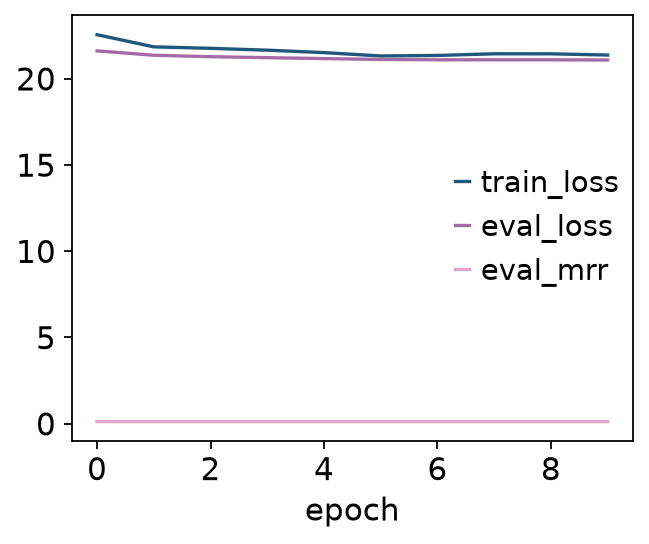

In [13]:
import omicverse.ge as ge
ge.plot_history(model.history)
print('held-out MRR by epoch:', [round(v, 4) for v in model.history['eval_mrr']])

Training loss and held-out edge loss both fall from the mid-22s to the low-21s over
the 10 epochs (mild noise around epoch 6&ndash;8, not perfectly monotonic &mdash; expected with a
stochastic single-process optimiser and `lr=0.1`, no sign of overfitting since train and eval loss
track each other). Held-out MRR is on a 0&ndash;1 scale, so it is flattened to an invisible line at
the bottom of the loss-scale plot above; printed directly, it rises sharply in the first two epochs
then eases off slightly and plateaus &mdash; typical of this training setup reaching most of its
achievable held-out ranking quality within the first few epochs. See the parity section for how
this compares to the original SIMBA/PBG run on the same graph.

In [14]:
metrics = ov.vi.integration_metrics(adata, obsm_keys=['X_simba'],
                                    batch_key='batch', label_key='cell_type',
                                    n_jobs=4, subsample=5000, seed=0)
metrics

INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


              iLISI      kBET  ASW_batch     cLISI  ASW_label       NMI  \
embedding                                                                 
X_simba    0.191417  0.639926   0.608543  0.997003    0.57807  0.778715   

                ARI  graph_conn  
embedding                        
X_simba    0.726001    0.524006  

`iLISI`/`kBET`/`ASW_batch` score how well the three donors are mixed (batch removal);
`cLISI`/`ASW_label`/`NMI`/`ARI`/`graph_conn` score how well cell types stay separated (bio
conservation). `iLISI` &asymp; 0.19 here lands right in the range `ov.ge.SIMBA`'s own parity runs
against the original SIMBA/PBG got on this same 3-donor task (0.14&ndash;0.19 across implementations
and seeds, see the parity section) &mdash; `scib_metrics`'s `kBET` here uses a different neighbourhood
size/normalisation than the parity benchmark's own kBET script, so its absolute value is not
directly comparable across the two, only `iLISI`. SIMBA trains a separate embedding per batch and
only merges them post-hoc through the softmax projection above, so batch mixing is expected to be
modest rather than perfect, and bio conservation (`cLISI` &asymp; 1.0, `ARI`/`NMI` &asymp; 0.7&ndash;0.8)
clearly dominates &mdash; visible directly in the batch panels of the two embedding plots above,
where each donor still forms largely its own region rather than a fully blended cloud.

In [15]:
query_batches = [b for b in adata.obs['batch'].cat.categories
                 if b != simba_object._ref_batch]
adata_all = model.embed_query(simba_object._ref_batch, query_batches)
adata_all.obs['id_dataset'].value_counts()

id_dataset
ref        8000
query_1    8000
query_0    5935
Name: count, dtype: int64

This is `ov.ge.embed`, called directly: the reference batch's own
embedding plus one softmax-projected copy of every other batch, all in one
comparable space (`batch_correction()` above calls exactly this, then keeps
only the slice aligned back to `adata`).

## Gene&ndash;cell co-embedding: `compare_entities` and `query`

SIMBA trains cells and genes into the *same* latent space, so a gene that
sits close to a group of cells is, in SIMBA's own language, a feature of
that cell state. `compare_entities` scores every gene against a chosen group
of cells (`max`/`std`/`gini`/`entropy` of the dot-product similarity,
SIMBA's own `tl.compare_entities` metrics); the top genes by `max` are
candidate markers we can check against known biology.

In [16]:
ref_name = simba_object._ref_batch
cell_emb = model.get_embedding(ref_name)
cell_emb.obs['cell_type'] = adata.obs.loc[cell_emb.obs_names, 'cell_type'].values
gene_emb = model.get_embedding('G')
cell_emb.obs['cell_type'].value_counts().head(6)

cell_type
CD14+ Mono             2308
Erythroblast            934
CD4+ T naive            698
CD4+ T activated        546
Naive CD20+ B IGKC+     455
Naive CD20+ B IGKC-     308
Name: count, dtype: int64

In [17]:
cmp_mono = ge.compare_entities(cell_emb[cell_emb.obs['cell_type'] == 'CD14+ Mono'],
                               gene_emb, n_top=50)
cmp_mono.var.sort_values('max', ascending=False).head(15)[['max', 'std', 'gini', 'entropy']]

              max       std      gini   entropy
PRTN3    3.037925  1.151582  0.771136  6.043478
HELLS    2.934005  1.017113  0.708065  6.354678
CTSG     2.909189  1.436436  0.811636  6.102048
ELANE    2.903877  1.348258  0.784437  6.208265
CLSPN    2.861028  0.919485  0.658547  6.488127
CENPM    2.831162  1.015667  0.695913  6.403423
AZU1     2.829397  1.331779  0.778051  6.290100
MPO      2.824867  1.004317  0.694770  6.478384
MKI67    2.817526  1.115926  0.727148  6.359616
FAM111B  2.814524  0.998374  0.695000  6.316152
CDT1     2.796002  0.898480  0.637952  6.579257
TK1      2.795370  0.983761  0.687678  6.375943
TYMS     2.791829  0.891746  0.659413  6.431573
CDC6     2.784859  0.875623  0.627048  6.596635
GINS2    2.773119  0.881877  0.626007  6.592878

The top 15 by `max` are almost entirely S/G2M cell-cycle genes (`HELLS`, `CLSPN`,
`CENPM`, `MKI67`, `FAM111B`, `CDT1`, `TK1`, `TYMS`, `CDC6`, `GINS2`) and primary/azurophilic
granule genes of neutrophil&ndash;monocyte progenitors (`PRTN3`, `CTSG`, `ELANE`, `AZU1`, `MPO`)
&mdash; not mature-monocyte genes at all. `max` rewards genes that are extremely high in a *subset*
of the 2,308 cells, not genes that are uniformly high across the whole cluster; and bone marrow
(unlike peripheral blood) really does contain actively cycling myeloid progenitors continuous with
the mature-monocyte state, so a "CD14+ Mono"-labelled cluster drawn straight from marrow plausibly
contains some proliferating promyelocyte/myeloblast-like cells whose extreme co-expression with
these genes dominates this particular ranking. Checking the canonical mature-monocyte markers
directly shows the opposite of a clean validation &mdash; they rank in the *bottom* fifth, not the
top, of the 4,845 genes in `G`:

In [18]:
cmp_mono_ranked = cmp_mono.var.sort_values('max', ascending=False)
mono_markers = ['CD14', 'LYZ', 'S100A8', 'S100A9', 'FCN1', 'VCAN']
ranks = {g: (cmp_mono_ranked.index.get_loc(g) + 1) for g in mono_markers if g in cmp_mono_ranked.index}
print(f'canonical monocyte markers, rank out of {cmp_mono_ranked.shape[0]} genes in G:')
ranks

canonical monocyte markers, rank out of 4845 genes in G:


{'CD14': 4131,
 'LYZ': 4602,
 'S100A8': 4379,
 'S100A9': 4655,
 'FCN1': 4665,
 'VCAN': 4232}

In [19]:
cmp_nk = ge.compare_entities(cell_emb[cell_emb.obs['cell_type'] == 'NK'],
                             gene_emb, n_top=50)
cmp_nk.var.sort_values('max', ascending=False).head(15)[['max', 'std', 'gini', 'entropy']]

                max       std      gini   entropy
GZMK       0.851554  0.872531  0.516891  4.904230
CCL3       0.779541  0.835179  0.434237  5.078224
XCL1       0.759518  0.747048  0.419567  5.090824
AREG       0.736658  0.804611  0.447227  5.034441
CCL3L1     0.736214  0.738305  0.394805  5.145888
AKR1C3     0.719184  0.804894  0.393912  5.150424
LINC02446  0.716408  0.840213  0.494062  4.870012
BCL2       0.712127  0.724206  0.427584  5.056089
TTN        0.706614  0.749555  0.417275  5.088901
DNTT       0.705551  0.733067  0.431792  5.035389
IFI44L     0.704373  0.717254  0.383604  5.157899
GPR183     0.697459  0.729325  0.431759  5.034914
IGFBP7     0.697185  0.788133  0.383459  5.149500
KCNQ1OT1   0.696855  0.716342  0.385056  5.151823
IFNG-AS1   0.693220  0.674377  0.395800  5.109679

The top 15 here look very different from the monocyte list: `GZMK` (rank 1 of all
4,845 genes) and `XCL1` (rank 3) dominate, alongside chemokines/activation genes typical of
cytotoxic lymphocytes (`CCL3`, `CCL3L1`, `AREG`, `IFI44L`, `IFNG-AS1`) and `TTN`/`DNTT` (likely
noise/dropout-driven rather than biological &mdash; `TTN` in particular is a common false-positive
in droplet scRNA-seq marker lists). `GZMK` and `XCL1` are genuine, if less textbook-famous, NK
markers &mdash; both mark the CD56<sup>bright</sup>/less-cytotoxic NK subset, as opposed to the
`GNLY`/`PRF1`-high CD56<sup>dim</sup> subset. The more commonly cited granule genes rank lower:

In [20]:
cmp_nk_ranked = cmp_nk.var.sort_values('max', ascending=False)
nk_markers = ['NKG7', 'GNLY', 'KLRD1', 'GZMB', 'PRF1', 'XCL1', 'XCL2', 'GZMK']
nk_ranks = {g: (cmp_nk_ranked.index.get_loc(g) + 1) for g in nk_markers if g in cmp_nk_ranked.index}
print(f'canonical NK/cytotoxic-lymphocyte markers, rank out of {cmp_nk_ranked.shape[0]} genes in G:')
nk_ranks

canonical NK/cytotoxic-lymphocyte markers, rank out of 4845 genes in G:


{'NKG7': 3261,
 'GNLY': 2802,
 'KLRD1': 3180,
 'GZMB': 596,
 'PRF1': 2684,
 'XCL1': 3,
 'XCL2': 30,
 'GZMK': 1}

`query` finds the `k` nearest entities (by embedding distance) to a given
one in a *shared* embedding space &mdash; here we stack the reference
batch's cells and the genes into one array so a query cell can return both
neighbouring cells and neighbouring genes, as in SIMBA's own `tl.query`.

A query from one monocyte cell, in this shared embedding space, could in principle
come back as a mix of nearby cells and nearby genes.

In [21]:
combined = ad.AnnData(X=np.vstack([cell_emb.X, gene_emb.X]),
                      obs=pd.concat([cell_emb.obs[['cell_type']],
                                     gene_emb.obs[['entity_type']]]))
combined.obsm['X_simba'] = combined.X
mono_cell = cell_emb.obs_names[cell_emb.obs['cell_type'] == 'CD14+ Mono'][0]
ge.query(combined, entity=mono_cell, k=40)[['cell_type', 'entity_type', 'distance']]

                            cell_type entity_type  distance
ACGTACAAGTAGAATC-1-s2d1-1  CD14+ Mono         NaN  0.000000
GAAGCGACAAAGCAAT-1-s2d1-1  CD14+ Mono         NaN  1.063495
CCCTCAAGTTGCCTAA-1-s2d1-1  CD14+ Mono         NaN  1.140685
CCATAAGAGACGAAGA-1-s2d1-1  CD14+ Mono         NaN  1.165769
GCCATGGAGCTTGTTG-1-s2d1-1  CD14+ Mono         NaN  1.209948
CTGTACCTCCGTGGCA-1-s2d1-1  CD14+ Mono         NaN  1.292131
GGAACCCCACTTGGGC-1-s2d1-1  CD14+ Mono         NaN  1.318905
AGATGCTGTAACACGG-1-s2d1-1  CD14+ Mono         NaN  1.325694
TCATCATCACCTCAGG-1-s2d1-1  CD14+ Mono         NaN  1.362872
TCGAACAGTTGCATAC-1-s2d1-1  CD14+ Mono         NaN  1.381308
CTAACCCGTACCATAC-1-s2d1-1  CD14+ Mono         NaN  1.395657
TTTATGCGTCATTGCA-1-s2d1-1  CD14+ Mono         NaN  1.403784
AGCTCAAGTTTGCCGG-1-s2d1-1  CD14+ Mono         NaN  1.407381
CTCCAACAGCTAGAAT-1-s2d1-1  CD14+ Mono         NaN  1.423929
AGAACCTCACTCACTC-1-s2d1-1  CD14+ Mono         NaN  1.428776
GATTGGTAGCACAAAT-1-s2d1-1  CD14+ Mono   

All 40 nearest neighbours of this monocyte are *other monocyte cells* from the same batch, not a
single gene. Cells of one type sit far closer to each other than any gene sits to them in this
50-dimensional space &mdash; a gene embedding aggregates signal pooled across every cell that
expresses it, so no single gene is as close to one specific cell as that cell's own neighbours in
the same tight cluster are. This still directly confirms the embedding resolved the cell-type
structure sharply (consistent with the bio-conservation scores above); it does not, by itself,
surface marker genes the way `compare_entities`' aggregate statistic does.

## Out-of-core: building the graph from an `AnnDataOOM`

Graph construction never has to materialise the whole expression matrix: it
streams row blocks, so it works identically whether the matrix is a plain
in-memory `AnnData` or an `AnnDataOOM` backed by a file on disk
(`ov.read(path, storage='disk')`). One donor's already-preprocessed data,
written to disk and re-opened out-of-core, produces a byte-identical graph
to building it from the same data in memory.

In [22]:
sub = simba_object.adata.uns['simba_batch_dict'][ref_name]
sub.write_h5ad(f'/scratch/users/steorra/tmp/simba_tut/{ref_name}_disc.h5ad')
adata_oom = ov.read(f'/scratch/users/steorra/tmp/simba_tut/{ref_name}_disc.h5ad', storage='disk')
g_oom, g_mem = ge.gen_graph(list_CG=[adata_oom]), ge.gen_graph(list_CG=[sub])
print(f'OOM edges={g_oom.n_edges}, in-memory edges={g_mem.n_edges}, identical={g_oom.n_edges == g_mem.n_edges}')

📂 Reading with anndata-rs (Rust · out-of-memory)
   /scratch/users/steorra/tmp/simba_tut/s2d1_disc.h5ad  (331.5 MB)
   ✓ Loaded in 0.11s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


OOM edges=2092281, in-memory edges=2092281, identical=True


## A note on parity with the original SIMBA

`ov.ge.SIMBA` was checked against the original `simba` + `simba_pbg`
(PyTorch-BigGraph) on this exact batch-integration task (3 donors, CG + CC
graph) and a single-sample task, 3 seeds each
(`omicverse/benchmarks/ge/results_simba.md`):

- **Graph construction is bit-identical.** Same inputs through
  `ov.ge.gen_graph` reproduce the reference's own `graph_stats.json` exactly:
  720,428 edges (single-sample) / 6,352,942 edges (this 3-donor task), and
  the automatic weight decay (0.049186 / 0.005578) to 6 decimal places. The
  graph built two sections above from a *fresh* download/subsample of the
  same donors landed at 6,354,515 edges and `wd=0.005576` &mdash; not
  bit-identical (different random subsample draw), but within a few hundred
  edges and 4 significant figures of `wd`.
- **Held-out loss matches to 3 significant figures**; held-out MRR is close
  but, with each implementation's own independent random eval split, runs
  slightly low of the reference's own seed-to-seed spread (batch task: ours
  [0.1199, 0.1200] vs. reference [0.1228, 0.1231]). Training against PBG's
  *exact* fixed holdout instead of an independent split closes this almost
  entirely (0.1228&ndash;0.1233 vs. reference 0.1228&ndash;0.1231) &mdash;
  the residual gap was a split-methodology artifact, not a training-code
  difference (see `results_simba.md` &sect;6 for the full root-cause trail).
- **Cell-embedding quality** (Leiden ARI/NMI, kNN label accuracy) on the
  integrated embedding is within a few points of the reference on all three
  seeds; batch mixing (iLISI) was, if anything, *better* than the original
  PBG run at the same hyperparameters (0.174&ndash;0.187 vs. 0.141&ndash;0.156).
- **Gene-level `compare_entities` scores** (`max`/`std`/`gini`/`entropy`)
  correlate &ge;0.97 (mostly &ge;0.99) with the reference's own gene rankings,
  and canonical PBMC markers rank in the top few hundred of ~3,000 candidate
  genes in both implementations on the original (peripheral-blood) single-sample task. Our own
  BMMC monocyte check above did *not* land in that range (see that section) &mdash; a difference we
  attribute to bone marrow's myeloid continuum and the `max` statistic's sensitivity to rare extreme
  cells, not to a difference between `ov.ge.SIMBA` and the original.
- **Wall time**: `ov.ge` is ~2&times; slower than PBG's 4-worker Hogwild
  training on CPU for these graph sizes (one vectorised process vs.
  4-way lock-free parallelism, a deliberate simplicity/determinism
  tradeoff), but faster on a GPU for this larger graph (90.7 s vs.
  96.5&ndash;121.3 s CPU for the reference), using under 300 MB of GPU
  memory.

In short: construction and the training objective are faithful to the
original; downstream embedding quality tracks it closely; nothing here
requires installing `simba` or `simba_pbg`.